# 06 · Cuatro exámenes de origen rodante

Repetimos la evaluación completa en cuatro ventanas de 26 semanas que no se
pisan. Cada examen tiene sus propios train, validación, huecos y etiquetas.
Solo los primeros 22 orígenes de cada ventana tienen sus cuatro respuestas
dentro de esa ventana. Entrenamos únicamente LightGBM L1, sin cambiar sus parámetros.

El historial de entrenamiento crece: las ventas de un examen viejo pueden usarse
en un examen posterior porque entonces ya son pasado. Nunca se usan las ventas
del test para entrenar ni detener el modelo del mismo examen.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

import os
from pathlib import Path
from importlib.metadata import version
from io import BytesIO
from matplotlib.figure import Figure
from IPython.display import display, Image
import numpy as np
import pandas as pd

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow
from stockifai_forecast.datos import leer_movimientos, agregar_semanal, rellenar_ceros
from stockifai_forecast.features import construir_abt
from stockifai_forecast.evaluacion import dividir_por_fecha
from stockifai_forecast.backtesting import calcular_cortes, correr_examen, correr_backtesting, resumir

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
raiz_repo = Path("..").resolve()
mlflow.set_tracking_uri((raiz_repo / "mlruns").as_uri())
mlflow.set_experiment("stockifai_backtesting")
print("Versiones:", {p: version(p) for p in ["lightgbm", "pandas", "mlflow"]})

Versiones: {'lightgbm': '4.7.0', 'pandas': '3.0.6', 'mlflow': '3.17.0'}


2026/11/03 01:47:22 INFO mlflow.tracking.fluent: Experiment with name 'stockifai_backtesting' does not exist. Creating a new experiment.


## 1. Preparar una única ABT y ubicar los cuatro cortes

Las features de cada fila solo usan su pasado y el calendario conocido. Por eso
podemos construir la ABT una vez y aplicar cortes diferentes. Las etiquetas de
universo y segmento sí se recalculan dentro de cada examen y de cada validación.


In [3]:
mov = leer_movimientos("../data/raw/Import-Movimientos.xlsx")
serie = rellenar_ceros(agregar_semanal(mov))
abt = construir_abt(serie)
cortes = calcular_cortes(abt)
assert cortes[-1] == dividir_por_fecha(abt)["inicio_test"]
ventanas = pd.DataFrame({"examen": range(1, 5), "inicio_test": cortes})
ventanas["fin_test"] = ventanas["inicio_test"] + pd.Timedelta(weeks=25)
ventanas["ultimo_origen_evaluable"] = ventanas["inicio_test"] + pd.Timedelta(weeks=21)
display(ventanas)

,examen,inicio_test,fin_test,ultimo_origen_evaluable
0,1,2023-07-31,2024-01-22,2023-12-25
1,2,2024-01-29,2024-07-22,2024-06-24
2,3,2024-07-29,2025-01-20,2024-12-23
3,4,2025-01-27,2025-07-21,2025-06-23


## 2. Repetir TODO por examen y registrar MLflow

`correr_backtesting` crea un run padre llamado `backtesting` y cuatro hijos.
Registra fechas, filas, repuestos por grupo, MAE, conteos y la mejor iteración
de cada horizonte. No guarda los modelos de estos exámenes.

Las funciones anteriores permanecen iguales. El tracking está desactivado por
defecto en la función; aquí lo habilitamos para guardar la ejecución real.
Las tablas de auditoría se devuelven en `metricas.attrs["examenes"]`, sin guardar
copias de toda la ABT ni modelos en memoria. Reejecutar crea otra familia de runs.


In [4]:
metricas = correr_backtesting(serie, abt, registrar_mlflow=True)
detalles = metricas.attrs["examenes"]
run_ids = metricas.attrs["run_ids"]
resumen = resumir(metricas)
print("Cuatro exámenes terminados.")
display(pd.DataFrame([
    {"examen": i, "inicio_test": d["inicio_test"], "fin_test": d["fin_test"],
     "inicio_fit": d["fechas"]["fit"]["inicio"], "fin_fit": d["fechas"]["fit"]["fin"],
     "inicio_val": d["inicio_val"], "fin_val": d["fechas"]["val"]["fin"],
     "ultimo_origen_test": d["fechas"]["test"]["fin"],
     "filas_train_antes_universo": d["filas"]["train"],
     "filas_fit": d["filas"]["fit"], "filas_val": d["filas"]["val"],
     "filas_test": d["filas"]["test"], "universo": d["repuestos"]["total"],
     "excluidas_sin_prom_8": d["filas"]["test_excluidas_sin_prom_8"]}
    for i, d in enumerate(detalles, start=1)
]))
display(pd.DataFrame([
    {"examen": i, "dimension": dimension, "grupo": grupo, "repuestos": n}
    for i, d in enumerate(detalles, start=1)
    for dimension in ["segmento", "grupo_historia"]
    for grupo, n in d["repuestos"][dimension].items()
]))
display(pd.DataFrame([
    {"examen": i, "horizonte": h, "mejor_iteracion": it,
     "mae_val": d["mae_validacion"][h]}
    for i, d in enumerate(detalles, start=1)
    for h, it in d["mejores_iteraciones"].items()
]))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001337 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1558
[LightGBM] [Info] Number of data points in the train set: 39051, number of used features: 17
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001563 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1558
[LightGBM] [Info] Number of data points in the train set: 39051, number of used features: 17
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001280 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1558
[LightGBM] [Info] Number of data p

,examen,inicio_test,fin_test,inicio_fit,fin_fit,inicio_val,fin_val,ultimo_origen_test,filas_train_antes_universo,filas_fit,filas_val,filas_test,universo,excluidas_sin_prom_8
0,1,2023-07-31,2024-01-22,2020-08-10,2023-04-03,2023-05-08,2023-06-26,2023-12-25,243054,39051,2520,7524,342,0
1,2,2024-01-29,2024-07-22,2020-08-10,2023-10-02,2023-11-06,2023-12-25,2024-06-24,323576,54434,2992,8448,384,0
2,3,2024-07-29,2025-01-20,2020-08-10,2024-04-01,2024-05-06,2024-06-24,2024-12-23,410891,67793,3200,9306,423,0
3,4,2025-01-27,2025-07-21,2020-08-10,2024-09-30,2024-11-04,2024-12-23,2025-06-23,503231,83760,3480,10032,456,0


,examen,dimension,grupo,repuestos
0,1,segmento,frecuencia_alta,110
1,1,segmento,intermitente,232
2,1,grupo_historia,10-25,204
3,1,grupo_historia,26+,138
4,2,segmento,frecuencia_alta,102
5,2,segmento,intermitente,282
6,2,grupo_historia,10-25,217
7,2,grupo_historia,26+,167
8,3,segmento,frecuencia_alta,96
9,3,segmento,intermitente,327


,examen,horizonte,mejor_iteracion,mae_val
0,1,1,230,0.760554
1,1,2,205,0.773610
2,1,3,234,0.773283
3,1,4,245,0.764026
4,2,1,157,0.472782
5,2,2,223,0.477222
6,2,3,115,0.466538
7,2,4,227,0.426056
8,3,1,337,0.447612
9,3,2,72,0.428290


## 3. Control de cordura: reproducir el examen 4

En el corte único obtuvimos MAE total medio de 0,7074 con cero, 0,3899 con prom_8
y 0,3036 con L1. El examen 4 tiene exactamente los mismos cortes, etiquetas,
features, parámetros y filas. Comprobamos la diferencia antes de interpretar
los otros exámenes. La tolerancia de 0,00005 corresponde al redondeo a cuatro decimales.


In [5]:
control = (metricas.loc[(metricas["examen"] == 4) & (metricas["agrupacion"] == "total")]
           .groupby("baseline")["mae"].mean().rename("MAE examen 4").to_frame())
control["Referencia notebook 05"] = pd.Series({"cero": 0.7074, "prom_8": 0.3899, "lightgbm_l1": 0.3036})
control["Diferencia"] = control["MAE examen 4"] - control["Referencia notebook 05"]
np.testing.assert_allclose(control["MAE examen 4"], control["Referencia notebook 05"], rtol=0, atol=0.00005)
display(control)
print("OK: el examen 4 reproduce el corte único dentro del redondeo.")

OK: el examen 4 reproduce el corte único dentro del redondeo.


,MAE examen 4,Referencia notebook 05,Diferencia
baseline,,,
cero,0.707436,0.7074,0.000036
lightgbm_l1,0.303606,0.3036,0.000006
prom_8,0.389902,0.3899,0.000002


## 4. Qué regla gana en cada examen y grupo

Cada celda promedia los MAE de t+1 a t+4. El resaltado marca el menor error por
columna dentro de ese examen. Los segmentos y tamaños de universo pueden variar
entre exámenes porque las etiquetas solo conocen el pasado de su propio corte.


In [6]:
por_examen = (metricas.groupby(["examen", "agrupacion", "grupo", "baseline"])["mae"]
              .mean().reset_index())
orden = ["cero", "prom_8", "lightgbm_l1"]
columnas = [("segmento", "intermitente"), ("segmento", "frecuencia_alta"),
            ("grupo_historia", "10-25"), ("grupo_historia", "26+"), ("total", "total")]
etiquetas_columnas = ["Intermitentes", "Frecuencia alta", "Historia 10-25", "Historia 26+", "Total"]
tablas = {}
for examen in range(1, 5):
    tabla = (por_examen.loc[por_examen["examen"] == examen]
             .pivot(index="baseline", columns=["agrupacion", "grupo"], values="mae")
             .reindex(index=orden, columns=columnas))
    tabla.columns = etiquetas_columnas
    tablas[examen] = tabla
    print(f"Examen {examen} · inicio {cortes[examen - 1]:%d/%m/%Y}")
    display(tabla.style.format("{:.4f}").highlight_min(axis=0))

Examen 1 · inicio 31/07/2023
Examen 2 · inicio 29/01/2024
Examen 3 · inicio 29/07/2024
Examen 4 · inicio 27/01/2025


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
cero,0.1494,3.3401,0.1476,2.6954,1.1757
prom_8,0.2678,1.4685,0.2653,1.2286,0.6540
lightgbm_l1,0.1518,1.2614,0.1521,1.0358,0.5087


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
cero,0.1082,3.0938,0.0841,1.9631,0.9013
prom_8,0.1758,1.3092,0.1369,0.9185,0.4768
lightgbm_l1,0.1086,1.2002,0.0842,0.8069,0.3985


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
cero,0.1094,3.9228,0.1002,2.1001,0.9749
prom_8,0.1824,2.0025,0.1555,1.1614,0.5955
lightgbm_l1,0.1098,1.8757,0.0979,1.0415,0.5106


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
cero,0.0800,3.1235,0.0562,1.5048,0.7074
prom_8,0.1392,1.3554,0.1006,0.7442,0.3899
lightgbm_l1,0.0804,1.1631,0.0564,0.6063,0.3036


## 5. Resumen de estabilidad

Primero promediamos los cuatro horizontes de cada examen. Después cada examen
pesa lo mismo, aunque tenga más repuestos o filas. Mínimo y máximo son los extremos
de esos promedios por examen, no los mejores y peores horizontes individuales.
Los empates numéricos cuentan como victoria para todos los empatados.
`n_examenes` informa cuántos exámenes tienen datos para ese grupo y método.


In [7]:
display(resumen.round({"mae_promedio": 4, "mae_min": 4, "mae_max": 4}))
# Los tres métodos deben usar la misma cantidad de filas en cada celda.
usadas = metricas.pivot(index=["examen", "horizonte", "agrupacion", "grupo"],
                        columns="baseline", values="n_filas")
assert (usadas["cero"] == usadas["prom_8"]).all()
assert (usadas["cero"] == usadas["lightgbm_l1"]).all()
print("OK: cobertura idéntica para los tres métodos en los cuatro exámenes.")

OK: cobertura idéntica para los tres métodos en los cuatro exámenes.


,agrupacion,grupo,baseline,mae_promedio,mae_min,mae_max,examenes_ganados,n_examenes
0,grupo_historia,10-25,cero,0.0970,0.0562,0.1476,3,4
1,grupo_historia,10-25,lightgbm_l1,0.0977,0.0564,0.1521,1,4
2,grupo_historia,10-25,prom_8,0.1646,0.1006,0.2653,0,4
3,grupo_historia,26+,cero,2.0659,1.5048,2.6954,0,4
4,grupo_historia,26+,lightgbm_l1,0.8726,0.6063,1.0415,4,4
5,grupo_historia,26+,prom_8,1.0132,0.7442,1.2286,0,4
6,segmento,frecuencia_alta,cero,3.3701,3.0938,3.9228,0,4
7,segmento,frecuencia_alta,lightgbm_l1,1.3751,1.1631,1.8757,4,4
8,segmento,frecuencia_alta,prom_8,1.5339,1.3092,2.0025,0,4
9,segmento,intermitente,cero,0.1118,0.0800,0.1494,4,4


## 6. MAE total por examen

La línea representa el MAE total medio de los cuatro horizontes, en unidades de
error por repuesto-semana. Más abajo es mejor. El gráfico permite ver si la
ventaja se repite o depende de un período particular.


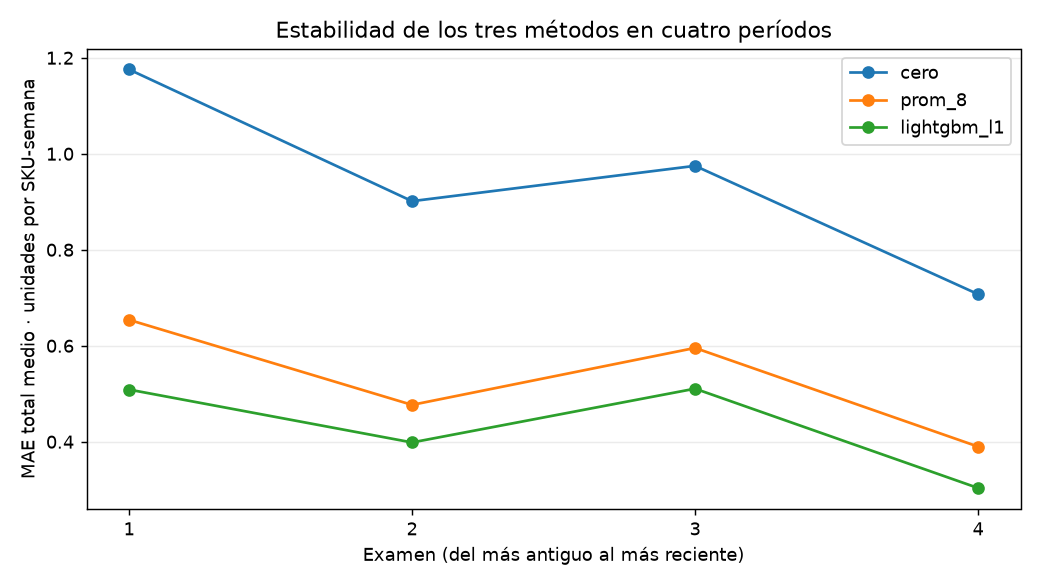

In [8]:
totales = (por_examen.loc[por_examen["agrupacion"] == "total"]
           .pivot(index="examen", columns="baseline", values="mae").reindex(columns=orden))
fig = Figure(figsize=(8, 4.5))
ax = fig.subplots()
for nombre, valores in totales.items():
    ax.plot(valores.index, valores, marker="o", label=nombre)
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Examen (del más antiguo al más reciente)")
ax.set_ylabel("MAE total medio · unidades por SKU-semana")
ax.set_title("Estabilidad de los tres métodos en cuatro períodos")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
buffer_figura = BytesIO()
fig.savefig(buffer_figura, format="png", dpi=130)
display(Image(data=buffer_figura.getvalue()))

## 7. Verificar la familia de runs

MLflow usa un run hijo por examen para poder abrir fechas, cantidades, métricas
y mejores iteraciones de ese examen. El padre agrupa todo y guarda el resumen.
No se guardan los dieciséis modelos del backtesting.


In [9]:
cliente = mlflow.tracking.MlflowClient()
padre = cliente.get_run(run_ids["padre"])
assert padre.info.status == "FINISHED"
assert not list(cliente.search_logged_models(experiment_ids=[padre.info.experiment_id]))
for i in range(1, 5):
    hijo = cliente.get_run(run_ids[f"examen_{i}"])
    assert hijo.info.status == "FINISHED"
    assert hijo.data.tags["mlflow.parentRunId"] == run_ids["padre"]
    assert len([k for k in hijo.data.metrics if k.startswith("mejor_iteracion/")]) == 4
    print(f"Examen {i}: {len(hijo.data.metrics)} métricas registradas.")
print("Padre:", run_ids["padre"])
print("OK: un padre y cuatro hijos terminados, sin modelos guardados.")

Examen 1: 308 métricas registradas.
Examen 2: 308 métricas registradas.
Examen 3: 308 métricas registradas.
Examen 4: 308 métricas registradas.
Padre: 465755b77d5146e483381f689e8505cf
OK: un padre y cuatro hijos terminados, sin modelos guardados.


## Funciones, métodos nuevos y decisiones

- `calcular_cortes`: resta bloques de 26 semanas al último corte; por ejemplo,
  si el último examen empieza en la semana 100, los anteriores empiezan en 74,
  48 y 22. Se devuelven ordenados de más antiguo a más nuevo.
- `correr_examen`: aplica el flujo completo a una ventana concreta. La ventana
  termina en un límite exclusivo; si termina antes de la semana 126, ningún
  target del examen puede corresponder a esa semana o una posterior.
- `correr_backtesting`: ejecuta los exámenes en orden y apila sus métricas en
  una tabla larga con la columna `examen`, como un UNION ALL de SQL.
- `resumir`: hace dos agrupaciones, como dos tablas dinámicas encadenadas:
  primero por examen y luego entre exámenes, sin ponderar por número de filas.
- `Timedelta(weeks=n)` mueve cortes una cantidad exacta de semanas; usar fechas
  evita confundir semanas con filas, ya que cada semana tiene muchos repuestos.
- `.notna().all(axis=1)` exige que todos los targets de una fila estén presentes.
- `.groupby(...).agg(...)` calcula promedio, mínimo, máximo y número de victorias
  por grupo/método, como varias funciones de resumen en una tabla dinámica.
- `.transform("min")` devuelve a cada método el mejor MAE de su examen/grupo;
  `np.isclose` identifica empates con tolerancia absoluta de 1e-10.
- `DataFrame.attrs` adjunta el detalle de los exámenes a la tabla sin convertir
  esos datos en features. Al exportar a CSV, ese detalle se guarda por separado.
- `mlflow.start_run(..., nested=True)` enlaza cada ficha de examen con su padre.

Se mantiene la validación de ocho semanas y la semilla 42. Las etiquetas de
fit/val usan exclusivamente historia anterior a inicio_val; las de test usan
historia anterior a inicio_test. No se reajusta con todo train. Si falta prom_8,
esa clave se excluye de los tres métodos y se informa; con estos datos no debería
ocurrir porque el universo ya exige diez semanas con venta anteriores al test.
Los ganadores se cuentan entre los tres métodos; para decidir el corte 10/26
se compara además L1 contra la MEJOR regla simple de cada examen.

Estos cuatro períodos ayudan a medir estabilidad. El cuarto ya había sido usado
para decidir y los anteriores son una revisión retrospectiva: no equivalen a
cuatro pruebas prospectivas totalmente nuevas ni prueban el rendimiento futuro.


## Lectura de esta ejecución

El examen 4 reproduce el notebook 05 dentro del redondeo. Los cuatro exámenes usaron ventanas sin superposición y la misma cobertura para los tres métodos.

- **10-25** (grupo_historia): L1 supera a la mejor regla simple en **1 de 4 exámenes**, promediando los cuatro horizontes.
- **26+** (grupo_historia): L1 supera a la mejor regla simple en **4 de 4 exámenes**, promediando los cuatro horizontes.
- **frecuencia_alta** (segmento): L1 supera a la mejor regla simple en **4 de 4 exámenes**, promediando los cuatro horizontes.
- **intermitente** (segmento): L1 supera a la mejor regla simple en **0 de 4 exámenes**, promediando los cuatro horizontes.
- **total** (total): L1 supera a la mejor regla simple en **4 de 4 exámenes**, promediando los cuatro horizontes.

En historia 10–25 gana 1/4, por lo que la regla solicitada recomienda **subir el corte a 26**. No se cambia automáticamente el umbral en el código.

En intermitentes, compará la cantidad de victorias y el rango del MAE para elegir la regla: las diferencias pequeñas no garantizan utilidad en reposición. El MAE no mide el costo de faltantes ni el sesgo.

Esta evaluación retrospectiva muestra estabilidad en varios períodos; las categorías y el catálogo cambian entre cortes. Para confirmar una política elegida a partir de estos resultados se necesita un período futuro.

**(a) ¿Se repite la mejora?** Sí: L1 supera a ambas reglas en frecuencia alta y en historia 26+ en los cuatro exámenes. En MAE total también gana 4/4.

**(b) ¿Qué elegir en intermitentes?** Con el criterio MAE, predecir cero: gana 4/4. L1 queda muy cerca de cero, pero no muestra una mejora consistente en este grupo.

**(c) ¿Corte 10 o 26?** Subir a 26 siguiendo la regla acordada: en historia 10–25 L1 gana solamente en el examen 3; pierde contra cero en los otros tres. Esta recomendación resume el MAE retrospectivo y no cambia automáticamente el universo de las funciones existentes.